<a href="https://colab.research.google.com/github/VTKhanhLinh/TH_MachineLearning/blob/main/Tuan_1/Bai_Tap_O_Lop/B%C3%A0i_2.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Bài 2:

DỰ ĐOÁN KHẢ NĂNG MẮC BỆNH DỰA TRÊN CHỈ SỐ BMI

Giả sử có một tập dữ liệu gồm:
- BMI: Chỉ số khối cơ thể của bệnh nhân.
- Mắc bệnh: Nhãn mục tiêu, bằng 1 nếu mắc bệnh và bằng 0 nếu không mắc bệnh.

Yêu cầu:
1. Tạo dữ liệu mẫu giả lập với BMI và nhãn mắc bệnh dựa trên mối liên hệ logistic.
2. Sử dụng scikit-learn xây dựng mô hình hồi quy Logistic.
3. Huấn luyện mô hình trên tập dữ liệu mẫu.
4. Dự đoán xác suất và nhãn mắc bệnh trên tập kiểm tra.
5. Đánh giá độ chính xác và ma trận nhầm lẫn.
6. Trực quan hóa dữ liệu và đường hồi quy Logistic.

In [1]:
#Khai báo thư viện
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report

np.random.seed(42)

In [12]:
#Tạo dữ liệu mẫu giả lập
# Số lượng bệnh nhân
n = 200

# Tạo BMI ngẫu nhiên từ 15 đến 40
bmi = np.random.uniform(15, 40, n)

# Tính xác suất mắc bệnh theo hàm Logistic
xac_suat = 1 / (1 + np.exp(-(bmi - 27) * 0.4))

# Tạo nhãn mắc bệnh (0 hoặc 1)
mac_benh = np.random.binomial(1, xac_suat)

# Tạo bảng dữ liệu
df = pd.DataFrame({
    "BMI": bmi,
    "Mắc bệnh": mac_benh
})

# Hiển thị 10 dòng đầu tiên bằng tiếng Việt
df_hien_thi = df.head(10).copy()
df_hien_thi["Mắc bệnh"] = df_hien_thi["Mắc bệnh"].map({
    0: "Không mắc bệnh",
    1: "Mắc bệnh"
})

print("10 bệnh nhân đầu tiên:")
display(df_hien_thi)

# Hiển thị kích thước dữ liệu
print("\nKích thước dữ liệu:", df.shape)
print("Số bệnh nhân:", df.shape[0])
print("Số thuộc tính:", df.shape[1])

# Thống kê số lượng từng nhãn
print("\nSố lượng bệnh nhân theo tình trạng:")
so_luong = df["Mắc bệnh"].value_counts()

print("Không mắc bệnh:", so_luong.get(0, 0))
print("Mắc bệnh:", so_luong.get(1, 0))

10 bệnh nhân đầu tiên:


,BMI,Mắc bệnh
0,32.680966,Mắc bệnh
1,18.813476,Không mắc bệnh
2,29.407209,Không mắc bệnh
3,30.167876,Mắc bệnh
4,25.603267,Mắc bệnh
5,33.411106,Mắc bệnh
6,38.359175,Mắc bệnh
7,38.139213,Mắc bệnh
8,26.270984,Không mắc bệnh
9,17.830951,Không mắc bệnh



Kích thước dữ liệu: (200, 2)
Số bệnh nhân: 200
Số thuộc tính: 2

Số lượng bệnh nhân theo tình trạng:
Không mắc bệnh: 102
Mắc bệnh: 98


In [13]:
#Chia dữ liệu huấn luyện và kiểm tra
#Biến đầu vào
X = df[["BMI"]]
#Biến đầu ra
y = df["Mắc bệnh"]

#Chia dữ liệu huấn luyện và kiểm tra
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)

print("Số mẫu huấn luyện:", len(X_train))
print("Số mẫu kiểm tra:", len(X_test))



Số mẫu huấn luyện: 160
Số mẫu kiểm tra: 40


In [14]:
#Xây dựng và huấn luyện mô hình Logistic Regression

# Khởi tạo mô hình
model = LogisticRegression()

# Huấn luyện mô hình
model.fit(X_train, y_train)

# Hiển thị hệ số
print("Hệ số hồi quy:", model.coef_[0][0])
print("Hệ số chặn:", model.intercept_[0])

Hệ số hồi quy: 0.33315134214442244
Hệ số chặn: -8.899396021194494


In [15]:
#Dự đoán xác suất và nhãn mắc bệnh
# Dự đoán xác suất mắc bệnh
y_prob = model.predict_proba(X_test)[:, 1]

# Dự đoán nhãn 0 hoặc 1
y_pred = model.predict(X_test)

# Tạo bảng so sánh kết quả
ket_qua = pd.DataFrame({
    "BMI": X_test["BMI"].values,
    "Thực tế": y_test.values,
    "Xác suất măc bệnh": y_prob,
    "Dự đoán": y_pred
})

print(ket_qua.head(15))

          BMI  Thực tế  Xác suất măc bệnh  Dự đoán
0   18.903815        0           0.069038        0
1   20.549304        1           0.113713        0
2   32.367412        1           0.868053        1
3   29.755767        1           0.733759        1
4   19.767193        0           0.089976        0
5   38.359175        1           0.979767        1
6   25.019077        0           0.362563        0
7   23.891818        1           0.280940        0
8   30.836955        1           0.798022        1
9   26.901260        0           0.515694        1
10  38.021047        1           0.977409        1
11  37.932839        1           0.976751        1
12  29.407209        0           0.710467        1
13  29.884625        1           0.742061        1
14  17.664956        0           0.046784        0


In [19]:
# Đánh giá độ chính xác của mô hình

# Tính Accuracy
accuracy = accuracy_score(y_test, y_pred)

print(f"Độ chính xác của mô hình: {accuracy * 100:.2f}%")

# Tạo báo cáo phân loại
bao_cao = classification_report(
    y_test,
    y_pred,
    labels=[0, 1],
    target_names=["Không mắc bệnh", "Mắc bệnh"],
    output_dict=True,
    zero_division=0
)

# Chuyển báo cáo thành bảng
df_bao_cao = pd.DataFrame(bao_cao).T

# Đổi tên các cột sang tiếng Việt
df_bao_cao = df_bao_cao.rename(columns={
    "precision": "Precision",
    "recall": "Recall",
    "f1-score": "F1-score",
    "support": "Số lượng mẫu"
})

# Đổi tên các dòng tổng hợp
df_bao_cao = df_bao_cao.rename(index={
    "accuracy": "Độ chính xác chung",
    "macro avg": "Trung bình không trọng số",
    "weighted avg": "Trung bình có trọng số"
})

print("\nBáo cáo đánh giá mô hình:")
display(df_bao_cao.round(2))

#Accuracy - Tỷ lệ dự đoán đúng
#Precision - Trong các mẫu dự đoán mắc bệnh, bao nhiêu mẫu thực sự mắc bệnh
#Recall - Trong các mẫu thực sự mắc bệnh, mô hình phát hiện được bao nhiêu
#F1-score	- Trung bình điều hòa của Precision và Recall

Độ chính xác của mô hình: 80.00%

Báo cáo đánh giá mô hình:


,Precision,Recall,F1-score,Số lượng mẫu
Không mắc bệnh,0.8,0.8,0.8,20.0
Mắc bệnh,0.8,0.8,0.8,20.0
Độ chính xác chung,0.8,0.8,0.8,0.8
Trung bình không trọng số,0.8,0.8,0.8,40.0
Trung bình có trọng số,0.8,0.8,0.8,40.0


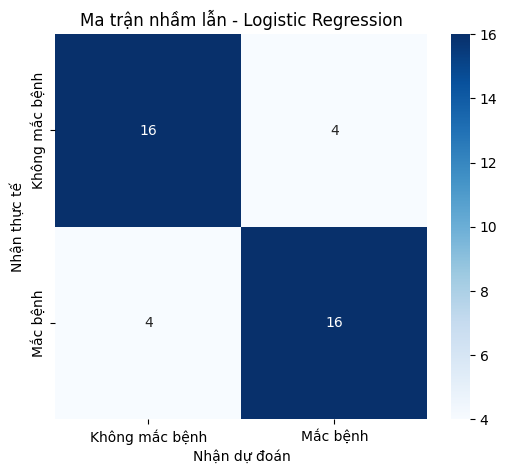

In [20]:
#Vẽ ma trận nhầm lẫn
# Tính ma trận nhầm lẫn
cm = confusion_matrix(y_test, y_pred, labels=[0, 1])

# Vẽ biểu đồ
plt.figure(figsize=(6, 5))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["Không mắc bệnh", "Mắc bệnh"],
    yticklabels=["Không mắc bệnh", "Mắc bệnh"]
)

plt.xlabel("Nhận dự đoán")
plt.ylabel("Nhận thực tế")
plt.title("Ma trận nhầm lẫn - Logistic Regression")
plt.show()

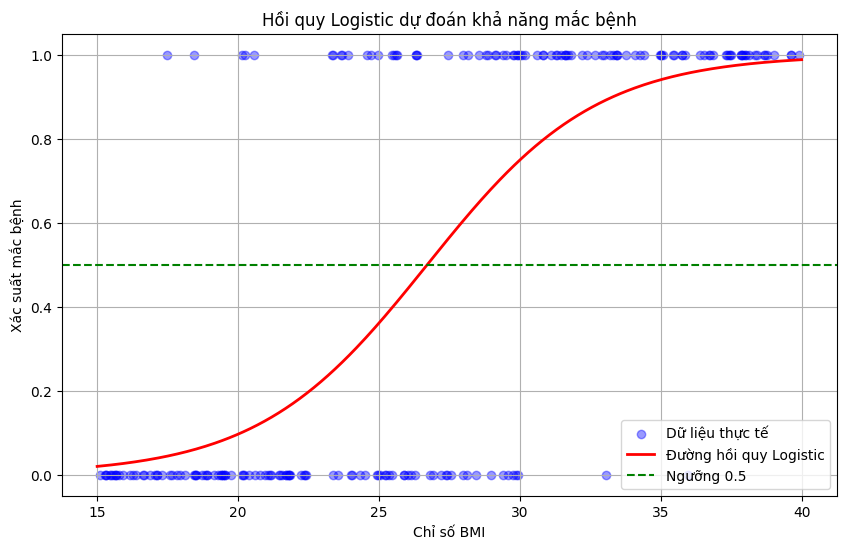

In [21]:
#Trực quan hóa dữ liệu và đường hồi quy Logistic
# Tạo dãy BMI để vẽ đường cong
bmi_range = np.linspace(15, 40, 300)

X_plot = pd.DataFrame({
    "BMI": bmi_range
})

# Dự đoán xác suất
prob_range = model.predict_proba(X_plot)[:, 1]

# Vẽ biểu đồ
plt.figure(figsize=(10, 6))

plt.scatter(
    df["BMI"],
    df["Mắc bệnh"],
    color="blue",
    alpha=0.4,
    label="Dữ liệu thực tế"
)

plt.plot(
    bmi_range,
    prob_range,
    color="red",
    linewidth=2,
    label="Đường hồi quy Logistic"
)

plt.axhline(
    y=0.5,
    color="green",
    linestyle="--",
    label="Ngưỡng 0.5"
)

plt.xlabel("Chỉ số BMI")
plt.ylabel("Xác suất mắc bệnh")
plt.title("Hồi quy Logistic dự đoán khả năng mắc bệnh")
plt.legend()
plt.grid(True)
plt.show()

In [22]:
#Thử dự đoán cho bệnh nhân mới (bổ sung)
# Dữ liệu BMI mới
bmi_moi = pd.DataFrame({
    "BMI": [18, 22, 25, 27, 30, 35, 40]
})

# Dự đoán xác suất
xac_suat_moi = model.predict_proba(bmi_moi)[:, 1]

# Dự đoán nhãn
nhan_moi = model.predict(bmi_moi)

# Tạo bảng kết quả
ket_qua_moi = pd.DataFrame({
    "BMI": bmi_moi["BMI"],
    "Xác suất": xac_suat_moi,
    "Dự đoán": nhan_moi
})

print(ket_qua_moi)

   BMI  Xác suất  Dự đoán
0   18  0.052022        0
1   22  0.172207        0
2   25  0.361096        0
3   27  0.523904        1
4   30  0.749349        1
5   35  0.940526        1
6   40  0.988187        1
